# AIFB Dataset Exploration and Analysis

## 1. Setup

Import the libraries, set random seeds, and define the local data files used throughout the notebook.


#### 1.1 Import Libraries

In [220]:
import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import rdflib as rdf
from rdflib import BNode, Literal, URIRef

plt.style.use("seaborn-v0_8-whitegrid")

#### 1.2 Set Random Seeds

In [221]:
random.seed(0)
np.random.seed(0)

#### 1.3 Define File Paths

In [222]:
# Locate the project root relative to the working directory
PROJECT_ROOT = Path(".")

if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = Path("..")

# Dataset directory
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# RDF graph
RDF_PATH = DATA_DIR / "aifbfixed_complete.n3"

# Node classification dataset
COMPLETE_LABELS_PATH = DATA_DIR / "completeDataset.tsv"
TRAIN_LABELS_PATH = DATA_DIR / "trainingSet.tsv"
TEST_LABELS_PATH = DATA_DIR / "testSet.tsv"

# Verify that all required files are available
required_files = {
    "RDF graph": RDF_PATH,
    "Complete labels": COMPLETE_LABELS_PATH,
    "Training split": TRAIN_LABELS_PATH,
    "Test split": TEST_LABELS_PATH,
}

for name, path in required_files.items():
    print(f"{name:<18} {path.exists()}  {path}")

RDF graph          True  ../data/raw/aifbfixed_complete.n3
Complete labels    True  ../data/raw/completeDataset.tsv
Training split     True  ../data/raw/trainingSet.tsv
Test split         True  ../data/raw/testSet.tsv


## 2. Load and Prepare the RDF Graph

Load the AIFB RDF graph, inspect its basic structure, and derive stable node and relation vocabularies for the following analyses.

#### 2.1 Load RDF Graph

In [223]:
# Load RDF knowledge graph
g = rdf.Graph()

# RDF data is stored as triples: subject, predicate, object.
g.parse(RDF_PATH, format="n3")

print(f"Loaded {len(g):,} RDF triples")

Loaded 29,226 RDF triples


#### 2.2 Create RDF Preview Table

In [224]:
# Convert RDF triples into a compact tabular preview.
# Each row represents a subject and each column represents a predicate.
rdf_rows = {}

for subject, predicate, obj in g:
    rdf_rows.setdefault(subject, {}).setdefault(predicate, []).append(str(obj))

rdf_preview = pd.DataFrame.from_dict(
    {
        subject: {
            predicate: "; ".join(values[:4]) for predicate, values in predicates.items()
        }
        for subject, predicates in rdf_rows.items()
    },
    orient="index",
).fillna("")

rdf_preview.head()

,http://swrc.ontoware.org/ontology#author,http://swrc.ontoware.org/ontology#title,http://swrc.ontoware.org/ontology#volume,http://www.w3.org/1999/02/22-rdf-syntax-ns#type,http://swrc.ontoware.org/ontology#month,http://swrc.ontoware.org/ontology#pages,http://swrc.ontoware.org/ontology#booktitle,http://swrc.ontoware.org/ontology#series,http://swrc.ontoware.org/ontology#year,http://swrc.ontoware.org/ontology#publication,...,http://swrc.ontoware.org/ontology#projectInfo,http://swrc.ontoware.org/ontology#financedBy,http://swrc.ontoware.org/ontology#carriedOutBy,http://www.w3.org/2002/07/owl#allValuesFrom,http://www.w3.org/2002/07/owl#onProperty,http://swrc.ontoware.org/ontology#edition,http://swrc.ontoware.org/ontology#type,http://swrc.ontoware.org/ontology#isbn,http://swrc.ontoware.org/ontology#finances,http://www.w3.org/2000/01/rdf-schema#range
http://www.aifb.uni-karlsruhe.de/Publikationen/viewPublikationOWL/id581instance,http://www.aifb.uni-karlsruhe.de/Publikationen...,Entwicklung eines Informationsportals fÃ¼r die...,50,http://swrc.ontoware.org/ontology#Publication;...,September,208-213,"INFORMATIK 2004 - Informatik verbindet, GI-Jah...",LNI,2004,,...,,,,,,,,,,
http://www.aifb.uni-karlsruhe.de/Publikationen/viewPublikationOWL/id512instance,http://www.aifb.uni-karlsruhe.de/Personen/view...,An Information Food Chain for Advanced Applica...,,http://swrc.ontoware.org/ontology#InProceeding...,September,,ECDL 2000 - Proceedings of the Fourth European...,,2000,,...,,,,,,,,,,
http://www.aifb.uni-karlsruhe.de/Publikationen/viewPublikationOWL/id568instance,http://www.aifb.uni-karlsruhe.de/Publikationen...,Knowledge Engineering: Principles and Methods,25,http://swrc.ontoware.org/ontology#Article; htt...,March,161-198,,,1998,,...,,,,,,,,,,
http://www.aifb.uni-karlsruhe.de/Publikationen/viewPublikationOWL/id1023instance,http://www.aifb.uni-karlsruhe.de/Publikationen...,Identification of standards on metadata for on...,,http://swrc.ontoware.org/ontology#Misc; http:/...,January,,,,2005,,...,,,,,,,,,,
http://www.aifb.uni-karlsruhe.de/Publikationen/viewPublikationOWL/id108instance,http://www.aifb.uni-karlsruhe.de/Personen/view...,An Approach for the Evolution of Ontology-base...,,http://swrc.ontoware.org/ontology#InProceeding...,,22-37,EKAW 2002 Workshop on Knowledge Management thr...,,2002,,...,,,,,,,,,,


#### 2.3 Build Node and Relation Vocabularies

In [225]:
# Count predicate frequencies
predicate_frequencies = Counter(g.predicates())

# Create a stable relation vocabulary.
# Relations are sorted by frequency first and lexicographically second.
relations = sorted(
    set(g.predicates()),
    key=lambda predicate: (
        -predicate_frequencies[predicate],
        str(predicate),
    ),
)

# Collect RDF subjects, objects, and all graph nodes
subjects = sorted(set(g.subjects()), key=str)
objects = sorted(set(g.objects()), key=str)
nodes = sorted(set(subjects).union(objects), key=str)

# Summarize the extracted vocabularies
pd.Series(
    {
        "RDF triples": len(g),
        "Subjects": len(subjects),
        "Objects": len(objects),
        "Nodes": len(nodes),
        "Relations": len(relations),
    },
    name="value",
).to_frame()

,value
RDF triples,29226
Subjects,2829
Objects,8096
Nodes,8285
Relations,47


**Insight.** The AIFB knowledge graph consists of RDF triples connecting subjects and objects through typed predicates. Extracting a stable node and relation vocabulary provides a consistent foundation for the subsequent graph analysis and the later conversion into a relational graph representation.

## 3. Explore the Label Tables

The TSV files define the researcher affiliation prediction task. They contain the labelled person nodes, their affiliation labels, and the predefined train/test split.

#### 3.1 Load Label Tables

In [226]:
# Load the complete label set and the predefined train/test splits
labels_df = pd.read_csv(COMPLETE_LABELS_PATH, sep="\t")
train_labels_df = pd.read_csv(TRAIN_LABELS_PATH, sep="\t")
test_labels_df = pd.read_csv(TEST_LABELS_PATH, sep="\t")

labels_df.head()

,id,person,label_affiliation
0,1,http://www.aifb.uni-karlsruhe.de/Personen/view...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...
1,2,http://www.aifb.uni-karlsruhe.de/Personen/view...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...
2,3,http://www.aifb.uni-karlsruhe.de/Personen/view...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...
3,4,http://www.aifb.uni-karlsruhe.de/Personen/view...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...
4,5,http://www.aifb.uni-karlsruhe.de/Personen/view...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...


#### 3.2 Add Readable Identifiers

In [227]:
def add_readable_ids(df: pd.DataFrame) -> pd.DataFrame:
    """Extract compact numeric person and affiliation IDs from RDF URIs."""
    df = df.copy()

    df["id"] = df["id"].astype(float).astype(int)

    df["person_id"] = df["person"].str.extract(r"/id(\d+)instance$").astype(int)

    df["affiliation_id"] = (
        df["label_affiliation"].str.extract(r"/id(\d+)instance$").astype(int)
    )

    return df


labels_df = add_readable_ids(labels_df)
train_labels_df = add_readable_ids(train_labels_df)
test_labels_df = add_readable_ids(test_labels_df)

labels_df.head()

,id,person,label_affiliation,person_id,affiliation_id
0,1,http://www.aifb.uni-karlsruhe.de/Personen/view...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,1855,1
1,2,http://www.aifb.uni-karlsruhe.de/Personen/view...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,1909,1
2,3,http://www.aifb.uni-karlsruhe.de/Personen/view...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,2040,3
3,4,http://www.aifb.uni-karlsruhe.de/Personen/view...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,46,2
4,5,http://www.aifb.uni-karlsruhe.de/Personen/view...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,3,2


#### 3.3 Add Research Group Names

In [228]:
SWRC = "http://swrc.ontoware.org/ontology#"
NAME = URIRef(SWRC + "name")

affiliation_lookup = []

# Look up a human-readable name for each affiliation URI
for affiliation_uri in sorted(labels_df["label_affiliation"].unique()):
    names = [str(name) for name in g.objects(URIRef(affiliation_uri), NAME)]

    affiliation_lookup.append(
        {
            "affiliation_id": int(
                affiliation_uri.rsplit("/id", 1)[1].replace("instance", "")
            ),
            "label_affiliation": affiliation_uri,
            "research_group": names[0] if names else "Unknown",
        }
    )

# Create a lookup table ordered by affiliation ID
affiliation_lookup = pd.DataFrame(affiliation_lookup).sort_values("affiliation_id")

affiliation_lookup

,affiliation_id,label_affiliation,research_group
0,1,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,Business Information and Communication Systems
1,2,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,Efficient Algorithms
2,3,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,Knowledge Management
3,4,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,Complexity Management


#### 3.4 Validate Label Tables and Train/Test Split

In [229]:
# Collect the labelled researchers in each dataset split
train_people = set(train_labels_df["person"])
test_people = set(test_labels_df["person"])
all_labelled_people = set(labels_df["person"])

# Validate the integrity of the label tables and the train/test split
label_validation = pd.Series(
    {
        "Complete rows": len(labels_df),
        "Training rows": len(train_labels_df),
        "Test rows": len(test_labels_df),
        "Unique labelled people": labels_df["person"].nunique(),
        "Unique affiliations": labels_df["label_affiliation"].nunique(),
        "Missing values": int(labels_df.isna().sum().sum()),
        "Duplicate people": int(labels_df.duplicated("person").sum()),
        "Train/test overlap": len(train_people & test_people),
        "People covered by train or test": len(train_people | test_people),
        "People missing from split": len(
            all_labelled_people - (train_people | test_people)
        ),
        "Split people missing from complete table": len(
            (train_people | test_people) - all_labelled_people
        ),
        "Training share": len(train_labels_df) / len(labels_df),
        "Test share": len(test_labels_df) / len(labels_df),
    },
    name="value",
).to_frame()

label_validation

,value
Complete rows,176.000000
Training rows,140.000000
Test rows,36.000000
Unique labelled people,176.000000
Unique affiliations,4.000000
Missing values,0.000000
Duplicate people,0.000000
Train/test overlap,0.000000
People covered by train or test,176.000000
People missing from split,0.000000


**Insight.** The validation confirms that the label tables are internally consistent. Every labelled researcher appears exactly once, the predefined training and test splits are mutually exclusive, and together they cover the complete set of labelled researchers.

#### 3.5 Analyze Class Distribution

In [230]:
# Count the number of labelled researchers per affiliation
class_balance = (
    labels_df["affiliation_id"]
    .value_counts()
    .sort_index()
    .rename_axis("affiliation_id")
    .reset_index(name="count")
)

class_balance["share"] = class_balance["count"] / len(labels_df)

# Attach human-readable research group names
class_balance = class_balance.merge(
    affiliation_lookup[["affiliation_id", "research_group"]],
    on="affiliation_id",
    how="left",
)

class_balance

,affiliation_id,count,share,research_group
0,1,73,0.414773,Business Information and Communication Systems
1,2,28,0.159091,Efficient Algorithms
2,3,60,0.340909,Knowledge Management
3,4,15,0.085227,Complexity Management


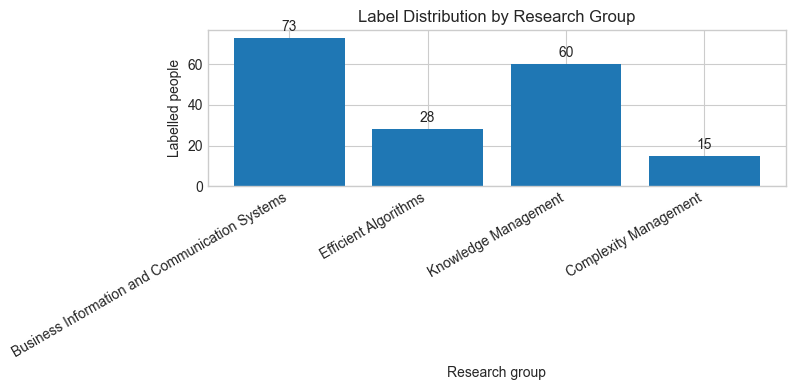

In [231]:
# Visualize the class distribution across research groups
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    class_balance["research_group"],
    class_balance["count"],
)

ax.set_title("Label Distribution by Research Group")
ax.set_xlabel("Research group")
ax.set_ylabel("Labelled people")

ax.bar_label(bars, padding=3)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Insight.** The researcher affiliation labels are moderately imbalanced. Business Information and Communication Systems (73 researchers) and Knowledge Management (60 researchers) account for most labelled instances, whereas Efficient Algorithms (28 researchers) and Complexity Management (15 researchers) are considerably smaller.

## 4. Explore the RDF Graph

This section analyzes the structure and semantic content of the AIFB RDF graph. The goal is to understand which types of entities and relations occur in the graph and how the graph structure supports the later R-GCN model.

#### 4.1 Define RDF Term Formatting

In [232]:
def compact_term(term):
    """Convert RDF terms into compact, human-readable labels."""
    if isinstance(term, Literal):
        return str(term)

    if isinstance(term, BNode):
        return "blank node"

    try:
        return g.namespace_manager.normalizeUri(term)
    except Exception:
        return str(term)

#### 4.2 Summarize RDF Graph Composition

In [233]:
# RDF nodes can appear either as subjects or objects and may represent
# entities (URIs), anonymous blank nodes, or literal values.
rdf_nodes = set(subjects).union(objects)

pd.Series(
    {
        "triples": len(g),
        "subjects": len(subjects),
        "predicates": len(relations),
        "objects": len(objects),
        "subject_or_object_nodes": len(rdf_nodes),
        "uri_nodes": sum(isinstance(node, URIRef) for node in rdf_nodes),
        "blank_nodes": sum(isinstance(node, BNode) for node in rdf_nodes),
        "literal_nodes": sum(isinstance(node, Literal) for node in rdf_nodes),
    },
    name="value",
).to_frame()

,value
triples,29226
subjects,2829
predicates,47
objects,8096
subject_or_object_nodes,8285
uri_nodes,2683
blank_nodes,152
literal_nodes,5450


**Insight.** With 29,226 triples and 47 distinct predicate types, the AIFB dataset represents a heterogeneous knowledge graph containing multiple entity types and semantic relationships. The large number of nodes compared to the number of relation types suggests that many entities share common relation semantics.

#### 4.3 Analyze Most Frequent Predicates

In [234]:
# Count and rank RDF predicates by their frequency in the graph
top_predicates = (
    pd.Series(predicate_frequencies, name="count")
    .sort_values(ascending=False)
    .rename_axis("predicate")
    .reset_index()
)

top_predicates["predicate"] = top_predicates["predicate"].map(compact_term)

top_predicates.head(15)

,predicate,count
0,:publication,4163
1,rdf:type,4124
2,:author,3986
3,:isAbout,2477
4,:name,1302
5,:year,1227
6,:title,1227
7,:publishes,1217
8,:hasProject,952
9,:projectInfo,952


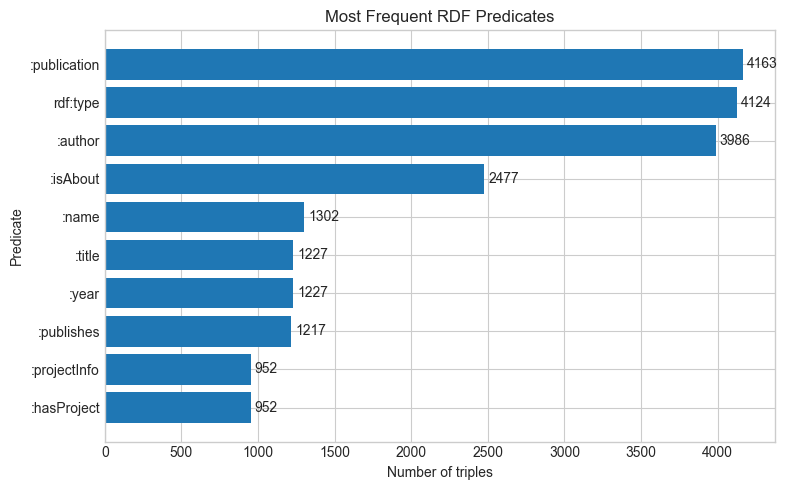

In [235]:
# Visualize the most frequent RDF predicates
fig, ax = plt.subplots(figsize=(8, 5))

top_predicates_plot = top_predicates.head(10).sort_values("count")

bars = ax.barh(
    top_predicates_plot["predicate"],
    top_predicates_plot["count"],
)

ax.set_title("Most Frequent RDF Predicates")
ax.set_xlabel("Number of triples")
ax.set_ylabel("Predicate")

ax.bar_label(bars, padding=3)

plt.tight_layout()
plt.show()

**Insight.** Predicate frequencies vary substantially across the graph, with :publication occurring most frequently (4,163 triples), followed closely by rdf:type (4,124) and :author (3,986).

#### 4.4 Analyze RDF Classes

In [236]:
RDF_TYPE = rdf.RDF.type
# rdf:type triples tell us which semantic classes occur in the graph, for example
# Person, Publication, Project, or ResearchTopic.
class_counts = (
    pd.Series(Counter(g.objects(None, RDF_TYPE)), name="count")
    .sort_values(ascending=False)
    .rename_axis("rdf_class")
    .reset_index()
)

# Replace long URIs with compact names
class_counts["rdf_class"] = class_counts["rdf_class"].map(compact_term)
class_counts.head(15)

,rdf_class,count
0,:Publication,1222
1,:Person,1045
2,:InProceedings,687
3,:TechnicalReport,169
4,:Article,161
5,owl:Restriction,152
6,:ResearchTopic,146
7,:InCollection,87
8,:Project,78
9,:PhDStudent,65


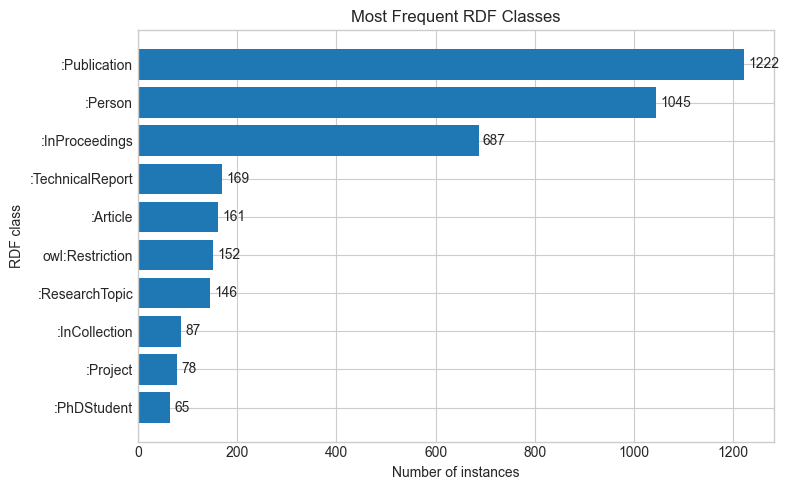

In [237]:
# Visualize the most frequent RDF classes
fig, ax = plt.subplots(figsize=(8, 5))

class_counts_plot = class_counts.head(10).sort_values("count")

bars = ax.barh(
    class_counts_plot["rdf_class"],
    class_counts_plot["count"],
)

ax.set_title("Most Frequent RDF Classes")
ax.set_xlabel("Number of instances")
ax.set_ylabel("RDF class")

ax.bar_label(bars, padding=3)

plt.tight_layout()
plt.show()

**Insight.** Publications and persons dominate the AIFB knowledge graph, while additional entity types such as research topics, projects, and publication categories provide rich contextual information. The presence of multiple semantic entity types highlights the heterogeneous nature of the graph and motivates the use of an R-GCN, which is designed to learn from graphs containing different node and relation types.

#### 4.5 Analyze Resource Graph Structure

In [238]:
# Build an undirected resource graph containing only RDF resources.
# Literal objects such as names, years, and phone numbers are excluded.
resource_edges = [
    (str(subject), str(obj)) for subject, _, obj in g if not isinstance(obj, Literal)
]

resource_graph = nx.Graph()
resource_graph.add_edges_from(resource_edges)

resource_degrees = dict(resource_graph.degree())

resource_graph_summary = pd.Series(
    {
        "Resource nodes": resource_graph.number_of_nodes(),
        "Resource edges": resource_graph.number_of_edges(),
        "Average node degree": (
            sum(resource_degrees.values()) / resource_graph.number_of_nodes()
        ),
        "Maximum node degree": max(resource_degrees.values()),
        "Graph density": nx.density(resource_graph),
        "Connected components": nx.number_connected_components(resource_graph),
    },
    name="value",
).to_frame()

resource_graph_summary

,value
Resource nodes,2835.000000
Resource edges,14624.000000
Average node degree,10.316755
Maximum node degree,1246.000000
Graph density,0.003640
Connected components,2.000000


#### 4.6 Analyze Degree Distribution

In [239]:
# Summarize the node degree distribution of the resource graph
degree_distribution = (
    pd.Series(resource_degrees, name="degree")
    .value_counts()
    .sort_index()
    .rename_axis("degree")
    .reset_index(name="node_count")
)

degree_distribution.head(15)

,degree,node_count
0,1,121
1,2,574
2,3,225
3,4,304
4,5,200
5,6,253
6,7,191
7,8,151
8,9,127
9,10,83


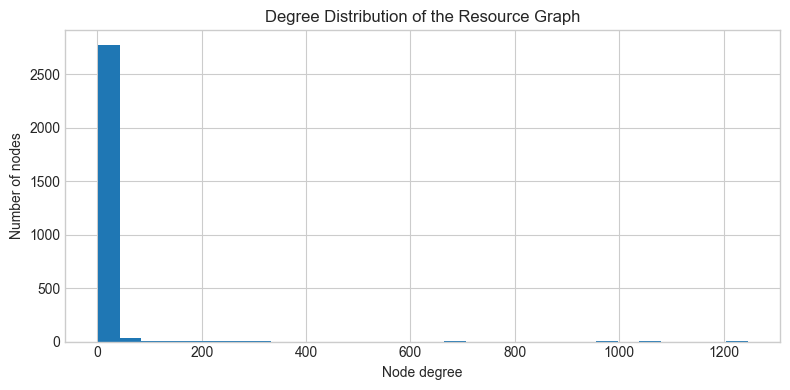

In [240]:
# Visualize the node degree distribution of the resource graph
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    list(resource_degrees.values()),
    bins=30,
)

ax.set_title("Degree Distribution of the Resource Graph")
ax.set_xlabel("Node degree")
ax.set_ylabel("Number of nodes")

plt.tight_layout()
plt.show()

**Insight.** The resource graph contains 2,835 resource nodes connected by 14,624 edges, resulting in a low overall graph density (0.0036). Despite the average node degree being approximately 10.3, the histogram shows that most nodes have only a few connections, while a small number of nodes exhibit exceptionally high degrees, with a maximum degree of 1,246. This indicates a highly skewed degree distribution in which a few hub entities are connected to many other nodes, whereas the majority of entities participate in only a limited number of relationships.

## 5. Connect Labels Back to the RDF Graph

This section verifies that the labelled person nodes from the TSV files are represented consistently in the RDF graph. It also inspects the local RDF neighborhood of one labelled person to illustrate the type of graph evidence available for prediction and explanation.

#### 5.1 Validate Affiliation Labels Against RDF Triples

In [241]:
# Extract affiliation triples from the RDF graph
AFFILIATION = URIRef(SWRC + "affiliation")

rdf_affiliations = pd.DataFrame(
    [
        {
            "person": str(person),
            "rdf_affiliation": str(affiliation),
        }
        for person, affiliation in g.subject_objects(AFFILIATION)
    ]
)

# Compare affiliation labels in the TSV files with the RDF graph
label_alignment = labels_df[["person", "label_affiliation", "affiliation_id"]].merge(
    rdf_affiliations,
    on="person",
    how="left",
    validate="one_to_one",
)

label_alignment["matches_tsv_label"] = (
    label_alignment["label_affiliation"] == label_alignment["rdf_affiliation"]
)

label_alignment_summary = pd.Series(
    {
        "TSV labelled people": len(labels_df),
        "People with RDF affiliation": int(
            label_alignment["rdf_affiliation"].notna().sum()
        ),
        "Matching affiliations": int(label_alignment["matches_tsv_label"].sum()),
        "Missing RDF affiliation": int(label_alignment["rdf_affiliation"].isna().sum()),
        "Mismatched affiliations": int(
            (
                ~label_alignment["matches_tsv_label"]
                & label_alignment["rdf_affiliation"].notna()
            ).sum()
        ),
    },
    name="value",
).to_frame()

label_alignment_summary

,value
TSV labelled people,176
People with RDF affiliation,176
Matching affiliations,176
Missing RDF affiliation,0
Mismatched affiliations,0


**Insight.** All 176 labelled researchers were successfully matched to affiliation triples in the RDF graph. No affiliations were missing or inconsistent, confirming that the label files are fully aligned with the underlying knowledge graph.

#### 5.2 Inspect an Example Person Neighborhood

##### 5.2.1 Helper Fuctions

In [242]:
def get_name(uri: str) -> str:
    """Return the swrc:name of an RDF resource if available; otherwise return a compact URI."""
    values = [str(value) for value in g.objects(URIRef(uri), NAME)]

    return values[0] if values else compact_term(URIRef(uri))


def get_readable_entity(term):
    """Return a human-readable label for an RDF resource or literal."""
    if isinstance(term, Literal):
        return str(term)

    if isinstance(term, BNode):
        return "blank node"

    if isinstance(term, URIRef):
        name = get_name(str(term))
        return name if name else compact_term(term)

    return str(term)

##### 5.2.2 Select Sample Person

In [243]:
# Select one labelled person for a local neighborhood inspection
sample_person_uri = labels_df.loc[119, "person"]

sample_person = URIRef(sample_person_uri)

sample_person_label = get_name(sample_person_uri)
sample_person_label

'Yu Li'

##### 5.2.3 Extract Local RDF Neighborhood

In [244]:
sample_neighborhood_records = []

# Outgoing triples: selected person -> object
for _, predicate, obj in g.triples((sample_person, None, None)):
    sample_neighborhood_records.append(
        {
            "direction": "outgoing",
            "subject": sample_person_label,
            "predicate": compact_term(predicate),
            "object": get_readable_entity(obj),
        }
    )

# Incoming triples: subject -> selected person
for subject, predicate, _ in g.triples((None, None, sample_person)):
    sample_neighborhood_records.append(
        {
            "direction": "incoming",
            "subject": get_readable_entity(subject),
            "predicate": compact_term(predicate),
            "object": sample_person_label,
        }
    )

sample_neighborhood = (
    pd.DataFrame(sample_neighborhood_records)
    .sort_values(["direction", "predicate", "subject"])
    .reset_index(drop=True)
)

sample_neighborhood.head(25)

,direction,subject,predicate,object
0,incoming,<http://www.aifb.uni-karlsruhe.de/Publikatione...,:author,Yu Li
1,incoming,<http://www.aifb.uni-karlsruhe.de/Publikatione...,:author,Yu Li
2,incoming,<http://www.aifb.uni-karlsruhe.de/Publikatione...,:author,Yu Li
3,incoming,Petri nets,:isWorkedOnBy,Yu Li
4,incoming,office information systems,:isWorkedOnBy,Yu Li
5,incoming,software engineering,:isWorkedOnBy,Yu Li
6,incoming,Business Information and Communication Systems,:member,Yu Li
7,outgoing,Yu Li,:affiliation,Business Information and Communication Systems
8,outgoing,Yu Li,:fax,+49 (721) 608 4548
9,outgoing,Yu Li,:name,Yu Li


##### 5.2.4 Visualize Local RDF Neighborhood

In [245]:
# Build a directed graph from the extracted RDF triples
neighborhood_graph = nx.DiGraph()
center_node = sample_person_label

neighborhood_graph.add_node(center_node, node_type="selected_person")

edge_labels = {}

for _, row in sample_neighborhood.iterrows():
    subject = row["subject"]
    obj = row["object"]
    predicate = row["predicate"]

    neighborhood_graph.add_node(
        subject,
        node_type="selected_person" if subject == center_node else "neighbor",
    )

    neighborhood_graph.add_node(
        obj,
        node_type="selected_person" if obj == center_node else "neighbor",
    )

    neighborhood_graph.add_edge(subject, obj)
    edge_labels[(subject, obj)] = predicate

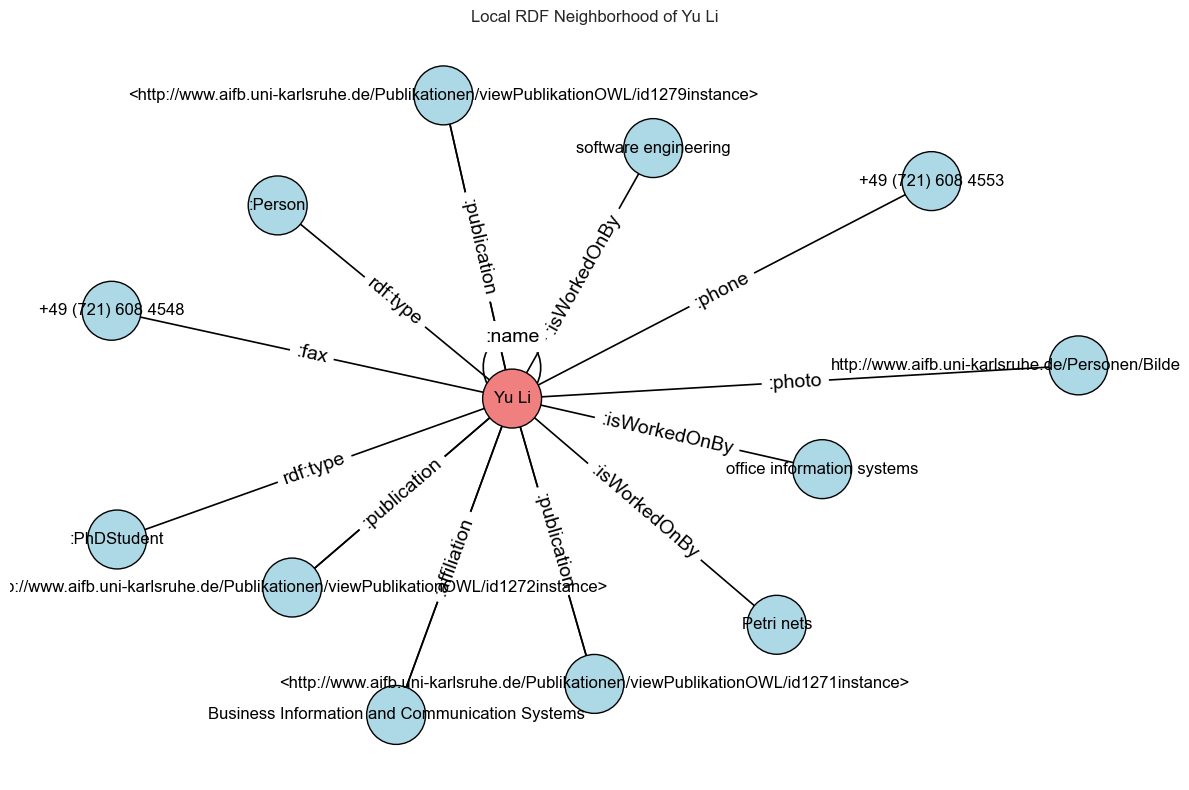

In [246]:
# Draw the local neighborhood graph
pos = nx.spring_layout(
    neighborhood_graph,
    seed=0,
    k=1.2,
)

node_colors = [
    "lightcoral" if node == center_node else "lightblue"
    for node in neighborhood_graph.nodes()
]

fig, ax = plt.subplots(figsize=(12, 8))

nx.draw_networkx_nodes(
    neighborhood_graph,
    pos,
    node_color=node_colors,
    node_size=1800,
    edgecolors="black",
    ax=ax,
)

nx.draw_networkx_edges(
    neighborhood_graph,
    pos,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=15,
    width=1.2,
    ax=ax,
)

nx.draw_networkx_labels(
    neighborhood_graph,
    pos,
    font_size=12,
    ax=ax,
)

nx.draw_networkx_edge_labels(
    neighborhood_graph,
    pos,
    edge_labels=edge_labels,
    font_size=14,
    ax=ax,
)

ax.set_title(f"Local RDF Neighborhood of {sample_person_label}")
ax.axis("off")

plt.tight_layout()
plt.show()

**Insight.** The visualization shows the immediate RDF neighborhood of one labelled researcher. This local structure illustrates the type of relational evidence available to the R-GCN and later to GNNExplainer when producing a local prediction explanation.

## 6. Prepare the Graph for R-GCN Encoding

This section illustrates how RDF terms are mapped to numeric node and relation IDs for relational graph neural network processing. The full model training pipeline is implemented in Notebook 02; here, the goal is only to inspect the resulting graph representation.

#### 6.1 Create Node and Relation Mappings

In [247]:
# Map RDF nodes and relations to integer IDs
relations_dict = {relation: idx for idx, relation in enumerate(relations)}

nodes_dict = {str(node): idx for idx, node in enumerate(nodes)}

pd.Series(
    {
        "Nodes": len(nodes_dict),
        "Relations": len(relations_dict),
        "Labelled people in node index": int(
            labels_df["person"].isin(nodes_dict).sum()
        ),
    },
    name="value",
).to_frame()

,value
Nodes,8284
Relations,47
Labelled people in node index,176


#### 6.2 Add Forward and Inverse Edges

In [248]:
# Remove target-label relations to prevent label leakage
TARGET_PREDICATES_TO_EXCLUDE = {URIRef(SWRC + "affiliation")}

model_triples = [
    (subject, predicate, obj)
    for subject, predicate, obj in g.triples((None, None, None))
    if predicate not in TARGET_PREDICATES_TO_EXCLUDE
]

# Create the graph representation with forward and inverse edges
edge_rows = []

for subject, predicate, obj in model_triples:
    source_id = nodes_dict[str(subject)]
    target_id = nodes_dict[str(obj)]
    relation_id = relations_dict[predicate]

    predicate_label = compact_term(predicate)

    edge_rows.extend(
        [
            {
                "source_id": source_id,
                "target_id": target_id,
                "edge_type": 2 * relation_id,
                "predicate": predicate_label,
                "direction": "forward",
            },
            {
                "source_id": target_id,
                "target_id": source_id,
                "edge_type": 2 * relation_id + 1,
                "predicate": predicate_label,
                "direction": "inverse",
            },
        ]
    )

edge_table = pd.DataFrame(edge_rows)

edge_table.head()

,source_id,target_id,edge_type,predicate,direction
0,7461,5954,4,:author,forward
1,5954,7461,5,:author,inverse
2,6609,7015,0,:publication,forward
3,7015,6609,1,:publication,inverse
4,7386,5525,4,:author,forward


#### 6.3 Summarize Model-Ready Graph Representation

In [249]:
# Summarize the model-ready graph representation
model_ready_summary = pd.Series(
    {
        "Nodes": len(nodes_dict),
        "RDF relations": len(relations_dict),
        "Edge types with inverse relations": 2 * len(relations_dict),
        "Directed edges with inverse relations": len(edge_table),
        "Labelled people in node index": int(
            labels_df["person"].isin(nodes_dict).sum()
        ),
    },
    name="value",
).to_frame()

model_ready_summary

,value
Nodes,8284
RDF relations,47
Edge types with inverse relations,94
Directed edges with inverse relations,58096
Labelled people in node index,176


#### 6.4 Inspect Encoded Edges

In [250]:
edge_table.sort_values(["source_id", "target_id", "edge_type"]).head(12)

,source_id,target_id,edge_type,predicate,direction
993,0,5525,41,:fax,inverse
21273,0,5527,41,:fax,inverse
51049,0,5527,43,:phone,inverse
30515,0,5530,41,:fax,inverse
19313,0,5532,41,:fax,inverse
49771,0,5532,43,:phone,inverse
11145,0,5533,41,:fax,inverse
41655,0,5533,43,:phone,inverse
51003,0,5534,41,:fax,inverse
34313,0,5534,43,:phone,inverse


**Insight.** Each RDF relation is represented by a forward edge and a corresponding inverse edge. This doubles the number of edge types and enables the R-GCN to propagate information in both directions during message passing.

## 7. Takeaways

* The AIFB dataset combines a heterogeneous RDF knowledge graph with a supervised researcher affiliation prediction task consisting of 176 labelled researchers across four research groups.
* The RDF graph contains 29,226 triples, 8,285 unique nodes, and 47 relation types, providing rich semantic information beyond the labelled researchers.
* Publications, researchers, research topics, and projects form the dominant semantic entities, while publication- and author-related predicates account for a large proportion of the graph’s relationships.
* The label tables are fully consistent with the RDF graph, with every labelled researcher mapped to exactly one affiliation and no missing or conflicting labels.
* The graph exhibits a sparse, heterogeneous structure with a small number of highly connected hub nodes and many sparsely connected entities.
* The RDF graph can be transformed into a model-ready representation by assigning numeric IDs to nodes and relations and introducing inverse edges, providing the input representation required for the R-GCN in the following notebook.